# Travel, Circadian Disruption, and NHL Market Efficiency
### 2024–25 NHL Season · Portfolio Analysis

**Research question.** Do travel distance and estimated residual circadian disruption predict team performance or betting market outcomes after accounting for scheduling, team characteristics, and market-implied probabilities?

**Scope.** Observational, one season analysis. Null results do not prove zero effects or perfect market efficiency. This notebook presents the final statistical analyses; the original research notebooks retain the upstream travel reconstruction, bookmaker cleaning, and extensive QA audit trail.

**Reproducibility.** This notebook runs from the two analysis-ready CSV datasets in data/processed/. The upstream reconstruction and cleaning procedures are documented in the supporting research notebooks. Reproducing the analysis requires those processed datasets and the Python dependencies used below.

## 1. Inputs and Setup

This notebook presents the final statistical analysis of NHL team performance and betting market efficiency. It uses two preprocessed datasets generated through the historical data reconstruction and validation procedures documented in 02_travel_reconstruction.ipynb. The notebook intentionally separates the final analysis from upstream NHL API retrieval, venue geocoding, and manual mapping corrections.

Execution environment: Run this notebook from the notebooks/ directory, using that directory as the working directory. Relative data paths assume this structure, with the required processed datasets located in ../data/processed/.

In [43]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

DATA_DIR = Path('../data/processed')
TEAM_PATH = DATA_DIR / 'analysis_team_game_mean_final.csv'
PUCK_PATH = DATA_DIR / 'analysis_puckline_team_final.csv'

for path in [TEAM_PATH, PUCK_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f'Missing {path}. Export the two final analysis DataFrames '
            'from 02_travel_reconstruction.ipynb as described above.'
        )

analysis_team_game_mean = pd.read_csv(TEAM_PATH)
analysis_puckline_team = pd.read_csv(PUCK_PATH)

print('Team-game dataset:', analysis_team_game_mean.shape)
print('Puck-line dataset:', analysis_puckline_team.shape)
assert len(analysis_team_game_mean) == 2624
assert analysis_team_game_mean['gameId'].nunique() == 1312
assert len(analysis_puckline_team) == 4848
assert analysis_puckline_team['gameId'].nunique() == 1312


Team-game dataset: (2624, 106)
Puck-line dataset: (4848, 122)


## 2. Performance Analysis: First Analytical Stage

This section examines whether travel distance and circadian disruption are associated with underlying NHL team performance, measured using expected goal differential, shot differential, and goal differential. Travel distance is scaled per 1,000 km, while absolute residual circadian displacement is measured in hours. Models account for relevant scheduling and team level factors, with standard errors clustered by game. Directional, interaction, and adaptation specifications provide secondary sensitivity analyses.

These performance models establish the first stage of the research. The subsequent sections address the broader betting market efficiency question by comparing observed outcomes with market-implied expectations.

### Primary Performance Models

*Source: original `02_travel_reconstruction.ipynb`, code cell 427 (zero-based index). Retained without changing the statistical specification.*

In [44]:
df = analysis_team_game_mean.copy()

df["travelDistance1000km"] = (
    pd.to_numeric(df["travelDistanceKm"], errors="coerce") / 1000
)

outcomes = [
    "xGoalDifferential",
    "shotDifferential",
    "goalDifferential"
]

exposures = [
    "travelDistance1000km",
    "absResidualCircadianDisplacement"
]

required = (
    outcomes
    + exposures
    + ["restDays", "backToBack",
       "home_or_away", "team", "opposingTeam", "gameId"]
)

model_df = df.dropna(subset=required).copy()

# Confirm the common estimation sample
print("Observations:", len(model_df))
print("Games:", model_df["gameId"].nunique())

model_specs = {
    "Schedule adjusted":
        "travelDistance1000km"
        " + absResidualCircadianDisplacement"
        " + C(home_or_away)"
        " + restDays"
        " + backToBack",

    "Team + opponent FE":
        "travelDistance1000km"
        " + absResidualCircadianDisplacement"
        " + C(home_or_away)"
        " + restDays"
        " + backToBack"
        " + C(team)"
        " + C(opposingTeam)"
}

results = []

for outcome in outcomes:
    for spec_name, rhs in model_specs.items():

        model = smf.ols(
            f"{outcome} ~ {rhs}",
            data=model_df
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": model_df["gameId"]}
        )

        for exposure in exposures:
            ci = model.conf_int().loc[exposure]

            results.append({
                "outcome": outcome,
                "model": spec_name,
                "exposure": exposure,
                "n": int(model.nobs),
                "coef": model.params[exposure],
                "ci_low": ci.iloc[0],
                "ci_high": ci.iloc[1],
                "p_value": model.pvalues[exposure],
                "adj_R2": model.rsquared_adj
            })

performance_results = pd.DataFrame(results)

print(
    performance_results.round({
        "coef": 4,
        "ci_low": 4,
        "ci_high": 4,
        "p_value": 4,
        "adj_R2": 4
    }).to_string(index=False)
)

Observations: 2592
Games: 1300
          outcome              model                         exposure    n    coef  ci_low  ci_high  p_value  adj_R2
xGoalDifferential  Schedule adjusted             travelDistance1000km 2592  0.0313 -0.0333   0.0958   0.3428  0.0212
xGoalDifferential  Schedule adjusted absResidualCircadianDisplacement 2592  0.0266 -0.2413   0.2946   0.8454  0.0212
xGoalDifferential Team + opponent FE             travelDistance1000km 2592  0.0356 -0.0275   0.0986   0.2689  0.1347
xGoalDifferential Team + opponent FE absResidualCircadianDisplacement 2592 -0.0029 -0.2591   0.2534   0.9825  0.1347
 shotDifferential  Schedule adjusted             travelDistance1000km 2592  0.2485 -0.1730   0.6700   0.2478  0.0108
 shotDifferential  Schedule adjusted absResidualCircadianDisplacement 2592  1.3152 -0.5168   3.1471   0.1594  0.0108
 shotDifferential Team + opponent FE             travelDistance1000km 2592  0.3040 -0.0890   0.6970   0.1295  0.1540
 shotDifferential Team + opponent

### Travel Direction Sensitivity

*Source: original `02_travel_reconstruction.ipynb`, code cell 429 (zero-based index). Retained without changing the statistical specification.*

In [45]:
df = analysis_team_game_mean.copy()

df["travelDistance1000km"] = (
    pd.to_numeric(df["travelDistanceKm"], errors="coerce") / 1000
)

# Restrict to observations with complete model variables
required = [
    "xGoalDifferential",
    "travelDistance1000km",
    "travelDirection",
    "absResidualCircadianDisplacement",
    "restDays",
    "backToBack",
    "home_or_away",
    "team",
    "opposingTeam",
    "gameId"
]

model_df = df.dropna(subset=required).copy()

# Explicit reference category: no timezone displacement
model_df["travelDirection"] = pd.Categorical(
    model_df["travelDirection"],
    categories=["none", "east", "west"]
)

formula = (
    "xGoalDifferential ~ "
    "travelDistance1000km"
    " + C(travelDirection, Treatment(reference='none'))"
    " + absResidualCircadianDisplacement"
    " + C(home_or_away)"
    " + restDays"
    " + backToBack"
    " + C(team)"
    " + C(opposingTeam)"
)

model = smf.ols(
    formula,
    data=model_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_df["gameId"]}
)

terms = [
    "travelDistance1000km",
    "C(travelDirection, Treatment(reference='none'))[T.east]",
    "C(travelDirection, Treatment(reference='none'))[T.west]",
    "absResidualCircadianDisplacement"
]

results = pd.DataFrame({
    "coefficient": model.params[terms],
    "ci_low": model.conf_int().loc[terms, 0],
    "ci_high": model.conf_int().loc[terms, 1],
    "p_value": model.pvalues[terms]
})

print("Observations:", int(model.nobs))
print("Games:", model_df["gameId"].nunique())

print("\nTravel direction counts:")
print(model_df["travelDirection"].value_counts())

print("\nDirection-specific model:")
print(results.round(4).to_string())

print("\nAdjusted R²:", round(model.rsquared_adj, 4))

Observations: 2592
Games: 1300

Travel direction counts:
travelDirection
none    1825
west     391
east     376
Name: count, dtype: int64

Direction-specific model:
                                                         coefficient  ci_low  ci_high  p_value
travelDistance1000km                                         -0.0041 -0.0847   0.0765   0.9200
C(travelDirection, Treatment(reference='none'))[T.east]       0.1366 -0.0777   0.3508   0.2116
C(travelDirection, Treatment(reference='none'))[T.west]       0.1222 -0.0749   0.3193   0.2242
absResidualCircadianDisplacement                             -0.0054 -0.2734   0.2625   0.9683

Adjusted R²: 0.1347


### Circadian Disruption & Back-to-Back Games: Sensitivity Anslysis

*Source: original `02_travel_reconstruction.ipynb`, code cell 430 (zero-based index). Retained without changing the statistical specification.*

In [46]:
df = analysis_team_game_mean.copy()

df["travelDistance1000km"] = (
    pd.to_numeric(df["travelDistanceKm"], errors="coerce") / 1000
)

required = [
    "xGoalDifferential",
    "travelDistance1000km",
    "absResidualCircadianDisplacement",
    "restDays",
    "backToBack",
    "home_or_away",
    "team",
    "opposingTeam",
    "gameId"
]

model_df = df.dropna(subset=required).copy()

formula = (
    "xGoalDifferential ~ "
    "travelDistance1000km"
    " + absResidualCircadianDisplacement * backToBack"
    " + C(home_or_away)"
    " + restDays"
    " + C(team)"
    " + C(opposingTeam)"
)

model = smf.ols(
    formula,
    data=model_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_df["gameId"]}
)

terms = [
    "travelDistance1000km",
    "absResidualCircadianDisplacement",
    "backToBack",
    "absResidualCircadianDisplacement:backToBack"
]

results = pd.DataFrame({
    "coefficient": model.params[terms],
    "ci_low": model.conf_int().loc[terms, 0],
    "ci_high": model.conf_int().loc[terms, 1],
    "p_value": model.pvalues[terms]
})

print("Observations:", int(model.nobs))
print("Games:", model_df["gameId"].nunique())

print("\nInteraction model:")
print(results.round(4).to_string())

print("\nAdjusted R²:", round(model.rsquared_adj, 4))

print("\nCircadian exposure by back-to-back:")
print(
    pd.crosstab(
        model_df["backToBack"],
        model_df["absResidualCircadianDisplacement"] > 0
    )
)

Observations: 2592
Games: 1300

Interaction model:
                                             coefficient  ci_low  ci_high  p_value
travelDistance1000km                              0.0406 -0.0243   0.1055   0.2197
absResidualCircadianDisplacement                 -0.0630 -0.3518   0.2257   0.6688
backToBack                                       -0.1647 -0.3058  -0.0237   0.0221
absResidualCircadianDisplacement:backToBack       0.4736 -0.3677   1.3150   0.2699

Adjusted R²: 0.1346

Circadian exposure by back-to-back:
absResidualCircadianDisplacement  False  True 
backToBack                                    
0                                  2089    105
1                                   365     33


### Back-to-Back Games & Rest Specification Sensitivity

*Source: original `02_travel_reconstruction.ipynb`, code cell 431 (zero-based index). Retained without changing the statistical specification.*

In [47]:
base = (
    "xGoalDifferential ~ "
    "travelDistance1000km"
    " + absResidualCircadianDisplacement * backToBack"
    " + C(home_or_away)"
    " + C(team)"
    " + C(opposingTeam)"
)

formulas = {
    "B2B_only": base,
    "B2B_plus_restDays": base + " + restDays"
}

terms = [
    "backToBack",
    "absResidualCircadianDisplacement",
    "absResidualCircadianDisplacement:backToBack"
]

rows = []

for name, formula in formulas.items():

    model = smf.ols(
        formula,
        data=model_df
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": model_df["gameId"]}
    )

    for term in terms:
        ci = model.conf_int().loc[term]

        rows.append({
            "model": name,
            "term": term,
            "coef": model.params[term],
            "ci_low": ci.iloc[0],
            "ci_high": ci.iloc[1],
            "p_value": model.pvalues[term],
            "adj_R2": model.rsquared_adj
        })

recovery_comparison = pd.DataFrame(rows)

print(recovery_comparison.round(4).to_string(index=False))

            model                                        term    coef  ci_low  ci_high  p_value  adj_R2
         B2B_only                                  backToBack -0.1760 -0.3144  -0.0375   0.0127  0.1349
         B2B_only            absResidualCircadianDisplacement -0.0692 -0.3566   0.2182   0.6370  0.1349
         B2B_only absResidualCircadianDisplacement:backToBack  0.4803 -0.3592   1.3199   0.2621  0.1349
B2B_plus_restDays                                  backToBack -0.1647 -0.3058  -0.0237   0.0221  0.1346
B2B_plus_restDays            absResidualCircadianDisplacement -0.0630 -0.3518   0.2257   0.6688  0.1346
B2B_plus_restDays absResidualCircadianDisplacement:backToBack  0.4736 -0.3677   1.3150   0.2699  0.1346


### Alternative Circadian Adaptation Assumptions: Sensitivity Analysis

*Source: original `02_travel_reconstruction.ipynb`, code cell 432 (zero-based index). Retained without changing the statistical specification.*

In [48]:
circadian_specs = {
    "Primary":
        "absResidualCircadianDisplacement",

    "East 1 / West 1.5":
        "absResidualCircadianDisplacement_east1_west1_5",

    "Symmetric 1 / 1":
        "absResidualCircadianDisplacement_symmetric1_1"
}

required = [
    "xGoalDifferential",
    "travelDistance1000km",
    "restDays",
    "backToBack",
    "home_or_away",
    "team",
    "opposingTeam",
    "gameId"
] + list(circadian_specs.values())

sensitivity_df = model_df.dropna(subset=required).copy()

rows = []

for spec_name, circadian_var in circadian_specs.items():

    formula = (
        "xGoalDifferential ~ "
        "travelDistance1000km"
        f" + {circadian_var}"
        " + C(home_or_away)"
        " + restDays"
        " + backToBack"
        " + C(team)"
        " + C(opposingTeam)"
    )

    model = smf.ols(
        formula,
        data=sensitivity_df
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": sensitivity_df["gameId"]}
    )

    ci = model.conf_int().loc[circadian_var]

    rows.append({
        "circadian_spec": spec_name,
        "n": int(model.nobs),
        "coef_per_hour": model.params[circadian_var],
        "ci_low": ci.iloc[0],
        "ci_high": ci.iloc[1],
        "p_value": model.pvalues[circadian_var],
        "adj_R2": model.rsquared_adj
    })

sensitivity_results = pd.DataFrame(rows)

print(sensitivity_results.round(4).to_string(index=False))

   circadian_spec    n  coef_per_hour  ci_low  ci_high  p_value  adj_R2
          Primary 2592        -0.0029 -0.2591   0.2534   0.9825  0.1347
East 1 / West 1.5 2592         0.0048 -0.2484   0.2580   0.9705  0.1347
  Symmetric 1 / 1 2592         0.0213 -0.2226   0.2652   0.8643  0.1347


### Performance Findings: Interpretation

Across the primary performance regressions, travel distance and residual circadian displacement were not statistically significant predictors of expected goal, shot, or goal differential after accounting for the specified controls. The back-to-back indicator was associated with a modest reduction in expected goal differential in some specifications (approximately −0.16 to −0.18), but this is a secondary observational association, not evidence of causation. The sensitivity specifications are intended to test stability, not to identify a winning specification.

### Figure 1: Travel and Circadian Exposure

Travel distance varies substantially, while nonzero modelled residual circadian displacement occurs in only 139 of 2,624 team game records. This imbalance limits statistical power for circadian comparisons.

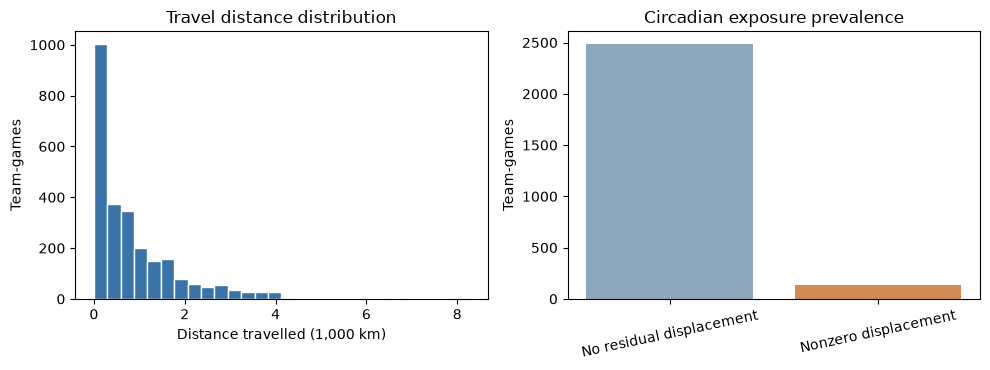

In [49]:
team_data = analysis_team_game_mean
travel_km = team_data["travelDistanceKm"].dropna()
exposed = (team_data["absResidualCircadianDisplacement"].fillna(0) > 0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(travel_km / 1000, bins=28, color="#3973a7", edgecolor="white")
axes[0].set(xlabel="Distance travelled (1,000 km)", ylabel="Team-games", title="Travel distance distribution")
axes[1].bar(["No residual displacement", "Nonzero displacement"], [(~exposed).sum(), exposed.sum()], color=["#8ca6bb", "#d48b51"])
axes[1].set(ylabel="Team-games", title="Circadian exposure prevalence")
axes[1].tick_params(axis="x", labelrotation=12)
fig.tight_layout()
plt.show()

## 3. Moneyline Market Efficiency

Market conditioned regressions use bookmaker implied log odds as a fixed offset. Mirrored team game observations are clustered by game; paired game models use one home team outcome per game.

### Moneyline Descriptive QA

*Source: original `02_travel_reconstruction.ipynb`, code cell 433 (zero-based index). Retained without changing the statistical specification.*

In [50]:
df = analysis_team_game_mean.copy()

# Validate the outcome and probability fields
df["win"] = pd.to_numeric(df["officialWin"], errors="coerce")
df["marketProb"] = pd.to_numeric(
    df["teamMlPowerProbMean"], errors="coerce"
)

df["circadianExposed"] = (
    df["absResidualCircadianDisplacement"] > 0
)

print("DATA VALIDATION")
print("Rows:", len(df))
print("Games:", df["gameId"].nunique())
print("Missing wins:", df["win"].isna().sum())
print("Missing probabilities:", df["marketProb"].isna().sum())
print("Win values:", sorted(df["win"].dropna().unique()))
print("Probability range:",
      df["marketProb"].min(), df["marketProb"].max())

# Verify complementary team probabilities and game outcomes
game_checks = df.groupby("gameId").agg(
    team_rows=("team", "size"),
    win_sum=("win", "sum"),
    probability_sum=("marketProb", "sum")
)

print("\nGAME-LEVEL CHECKS")
print("Games without exactly two team rows:",
      (game_checks["team_rows"] != 2).sum())
print("Games without exactly one winner:",
      (~np.isclose(game_checks["win_sum"], 1)).sum())
print("Games with probabilities not summing to one:",
      (~np.isclose(
          game_checks["probability_sum"], 1, atol=1e-8
      )).sum())

# Market residual
df["marketWinResidual"] = df["win"] - df["marketProb"]

def summarize_market(group):
    return pd.Series({
        "n": len(group),
        "actual_wins": group["win"].sum(),
        "expected_wins": group["marketProb"].sum(),
        "actual_win_pct": group["win"].mean(),
        "expected_win_pct": group["marketProb"].mean(),
        "wins_minus_expected": group["marketWinResidual"].sum(),
        "mean_residual": group["marketWinResidual"].mean()
    })

print("\nOVERALL MARKET SUMMARY")
print(summarize_market(df).round(4))

print("\nCIRCADIAN EXPOSURE GROUPS")
print(
    df.groupby("circadianExposed")
      .apply(summarize_market, include_groups=False)
      .round(4)
      .to_string()
)

print("\nHOME TEAMS BY CIRCADIAN EXPOSURE")
home_df = df[df["home_or_away"] == "HOME"]

print(
    home_df.groupby("circadianExposed")
           .apply(summarize_market, include_groups=False)
           .round(4)
           .to_string()
)

DATA VALIDATION
Rows: 2624
Games: 1312
Missing wins: 0
Missing probabilities: 0
Win values: [np.int64(0), np.int64(1)]
Probability range: 0.1684055083157559 0.8315944916842426

GAME-LEVEL CHECKS
Games without exactly two team rows: 0
Games without exactly one winner: 0
Games with probabilities not summing to one: 0

OVERALL MARKET SUMMARY
n                      2624.0
actual_wins            1312.0
expected_wins          1312.0
actual_win_pct            0.5
expected_win_pct          0.5
wins_minus_expected       0.0
mean_residual             0.0
dtype: float64

CIRCADIAN EXPOSURE GROUPS
                       n  actual_wins  expected_wins  actual_win_pct  expected_win_pct  wins_minus_expected  mean_residual
circadianExposed                                                                                                          
False             2485.0       1250.0      1246.0312           0.503            0.5014               3.9688         0.0016
True               139.0         62.0 

### Moneyline Market Calibration Simulation

*Source: original `02_travel_reconstruction.ipynb`, code cell 434 (zero-based index). Retained without changing the statistical specification.*

In [51]:
# One home-team probability and outcome per game
home = df.loc[
    df["home_or_away"] == "HOME",
    ["gameId", "marketProb", "win", "circadianExposed"]
].copy()

away = df.loc[
    df["home_or_away"] == "AWAY",
    ["gameId", "circadianExposed"]
].copy()

games = home.merge(
    away,
    on="gameId",
    suffixes=("_home", "_away"),
    validate="one_to_one"
)

p = games["marketProb"].to_numpy(dtype=float)
home_exposed = games["circadianExposed_home"].to_numpy(dtype=int)
away_exposed = games["circadianExposed_away"].to_numpy(dtype=int)
observed_home_win = games["win"].to_numpy(dtype=int)

# Total exposed wins per game:
# home exposed & home wins + away exposed & away wins
def exposed_wins(home_wins):
    return np.sum(
        home_exposed * home_wins
        + away_exposed * (1 - home_wins),
        axis=-1
    )

observed_all = exposed_wins(observed_home_win)
expected_all = np.sum(
    home_exposed * p + away_exposed * (1 - p)
)

observed_home = np.sum(home_exposed * observed_home_win)
expected_home = np.sum(home_exposed * p)

# Simulate game outcomes under market-implied probabilities
rng = np.random.default_rng(2026)
n_simulations = 100_000

simulated_all = np.empty(n_simulations)
simulated_home = np.empty(n_simulations)

batch_size = 1000

for start in range(0, n_simulations, batch_size):
    end = min(start + batch_size, n_simulations)
    size = end - start

    simulated_home_wins = (
        rng.random((size, len(games))) < p
    ).astype(int)

    simulated_all[start:end] = exposed_wins(
        simulated_home_wins
    )

    simulated_home[start:end] = np.sum(
        simulated_home_wins * home_exposed,
        axis=1
    )

def summarize_test(name, observed, expected, simulated):
    deviation = observed - expected
    simulated_deviation = simulated - expected

    # Two-sided probability of a deviation at least as extreme
    p_value = (
        np.sum(np.abs(simulated_deviation) >= abs(deviation)) + 1
    ) / (len(simulated) + 1)

    return {
        "group": name,
        "observed_wins": observed,
        "expected_wins": expected,
        "wins_minus_expected": deviation,
        "null_sd_wins": np.std(simulated, ddof=1),
        "two_sided_p": p_value,
        "null_2.5pct": np.quantile(simulated, 0.025),
        "null_97.5pct": np.quantile(simulated, 0.975)
    }

test_results = pd.DataFrame([
    summarize_test(
        "All circadian-exposed",
        observed_all,
        expected_all,
        simulated_all
    ),
    summarize_test(
        "Home circadian-exposed",
        observed_home,
        expected_home,
        simulated_home
    )
])

print(test_results.round(4).to_string(index=False))

print("\nQA — exposed observations:",
      int(home_exposed.sum() + away_exposed.sum()))

print("QA — exposed home observations:",
      int(home_exposed.sum()))

                 group  observed_wins  expected_wins  wins_minus_expected  null_sd_wins  two_sided_p  null_2.5pct  null_97.5pct
 All circadian-exposed             62        65.9688              -3.9688         5.116       0.4942         56.0          76.0
Home circadian-exposed             25        22.3040               2.6960         3.157       0.4319         16.0          28.0

QA — exposed observations: 139
QA — exposed home observations: 42


### Moneyline Regression Sample

*Source: original `02_travel_reconstruction.ipynb`, code cell 435 (zero-based index). Retained without changing the statistical specification.*

In [52]:
model_vars = [
    "gameId",
    "officialWin",
    "teamMlPowerProbMean",
    "travelDistanceKm",
    "absResidualCircadianDisplacement",
    "home_or_away",
]

market_model_df = analysis_team_game_mean[model_vars].copy()

print("Rows:", len(market_model_df))
print("Games:", market_model_df["gameId"].nunique())

print("\nMissing values:")
print(market_model_df.isna().sum())

print("\nTravel distance summary (km):")
print(
    market_model_df["travelDistanceKm"]
    .describe()
    .round(2)
)

print("\nCircadian displacement summary (hours):")
print(
    market_model_df["absResidualCircadianDisplacement"]
    .describe()
    .round(3)
)

print("\nExposure counts by home/away:")
print(
    pd.crosstab(
        market_model_df["home_or_away"],
        market_model_df["absResidualCircadianDisplacement"] > 0
    )
)

Rows: 2624
Games: 1312

Missing values:
gameId                               0
officialWin                          0
teamMlPowerProbMean                  0
travelDistanceKm                    32
absResidualCircadianDisplacement     0
home_or_away                         0
dtype: int64

Travel distance summary (km):
count    2592.00
mean      819.19
std       988.39
min         0.00
25%         0.00
50%       529.76
75%      1201.31
max      8254.02
Name: travelDistanceKm, dtype: float64

Circadian displacement summary (hours):
count    2624.000
mean        0.034
std         0.185
min         0.000
25%         0.000
50%         0.000
75%         0.000
max         2.792
Name: absResidualCircadianDisplacement, dtype: float64

Exposure counts by home/away:
absResidualCircadianDisplacement  False  True 
home_or_away                                  
AWAY                               1215     97
HOME                               1270     42


### Moneyline Analysis: Market-Adjusted Logistic Regression

*Source: original `02_travel_reconstruction.ipynb`, code cell 436 (zero-based index). Retained without changing the statistical specification.*

In [53]:
m = market_model_df.dropna().copy()

m["travel1000"] = (
    m["travelDistanceKm"].astype(float) / 1000
)

m["circadianHours"] = (
    m["absResidualCircadianDisplacement"].astype(float)
)

m["marketProb"] = (
    m["teamMlPowerProbMean"].astype(float)
)

m["win"] = m["officialWin"].astype(int)

m["home"] = (
    m["home_or_away"] == "HOME"
).astype(int)

# Market-implied log-odds
m["marketLogOdds"] = np.log(
    m["marketProb"] / (1 - m["marketProb"])
)

X = sm.add_constant(
    m[["travel1000", "circadianHours", "home"]]
)

model = sm.GLM(
    m["win"],
    X,
    family=sm.families.Binomial(),
    offset=m["marketLogOdds"]
)

result = model.fit(
    cov_type="cluster",
    cov_kwds={"groups": m["gameId"]}
)

print("MARKET-CONDITIONED LOGISTIC MODEL")
print("Observations:", len(m))
print("Games:", m["gameId"].nunique())

print("\nCOEFFICIENTS")
print(
    pd.DataFrame({
        "coefficient": result.params,
        "odds_ratio": np.exp(result.params),
        "p_value": result.pvalues,
        "CI_lower": result.conf_int()[0],
        "CI_upper": result.conf_int()[1]
    }).round(4).to_string()
)

print("\nMODEL FIT")
print("Deviance:", round(result.deviance, 3))
print("Pearson chi2:", round(result.pearson_chi2, 3))

MARKET-CONDITIONED LOGISTIC MODEL
Observations: 2592
Games: 1300

COEFFICIENTS
                coefficient  odds_ratio  p_value  CI_lower  CI_upper
const               -0.1441      0.8658   0.0475   -0.2866   -0.0016
travel1000           0.0387      1.0394   0.3938   -0.0502    0.1276
circadianHours      -0.1865      0.8299   0.3539   -0.5808    0.2078
home                 0.2372      1.2677   0.0429    0.0076    0.4668

MODEL FIT
Deviance: 3397.056
Pearson chi2: 2599.245


### Moneyline Analysis: Paired Game Market-Adjusted Logistic Regression

*Source: original `02_travel_reconstruction.ipynb`, code cell 437 (zero-based index). Retained without changing the statistical specification.*

In [54]:
# Use the travel-complete sample from the prior model
home_games = m.loc[
    m["home"] == 1,
    [
        "gameId", "win", "marketProb",
        "travel1000", "circadianHours"
    ]
].rename(columns={
    "win": "homeWin",
    "marketProb": "homeMarketProb",
    "travel1000": "homeTravel",
    "circadianHours": "homeCircadian"
})

away_games = m.loc[
    m["home"] == 0,
    ["gameId", "travel1000", "circadianHours"]
].rename(columns={
    "travel1000": "awayTravel",
    "circadianHours": "awayCircadian"
})

g = home_games.merge(
    away_games,
    on="gameId",
    validate="one_to_one"
)

g["travelDifference"] = (
    g["homeTravel"] - g["awayTravel"]
)

g["circadianDifference"] = (
    g["homeCircadian"] - g["awayCircadian"]
)

g["marketLogOdds"] = np.log(
    g["homeMarketProb"] / (1 - g["homeMarketProb"])
)

X_game = sm.add_constant(
    g[["travelDifference", "circadianDifference"]]
)

game_model = sm.GLM(
    g["homeWin"],
    X_game,
    family=sm.families.Binomial(),
    offset=g["marketLogOdds"]
)

game_result = game_model.fit(cov_type="HC1")

print("GAME-LEVEL MARKET MODEL")
print("Games:", len(g))

print("\nCOEFFICIENTS")
print(
    pd.DataFrame({
        "coefficient": game_result.params,
        "odds_ratio": np.exp(game_result.params),
        "p_value": game_result.pvalues,
        "CI_lower": game_result.conf_int()[0],
        "CI_upper": game_result.conf_int()[1]
    }).round(4).to_string()
)

print("\nQA")
print("Unique game IDs:", g["gameId"].nunique())
print("Home wins:", g["homeWin"].sum())
print("Circadian difference nonzero:",
      (g["circadianDifference"] != 0).sum())
print("Travel difference nonzero:",
      (g["travelDifference"] != 0).sum())

GAME-LEVEL MARKET MODEL
Games: 1292

COEFFICIENTS
                     coefficient  odds_ratio  p_value  CI_lower  CI_upper
const                     0.1333      1.1426   0.0298    0.0130    0.2536
travelDifference          0.0528      1.0542   0.2700   -0.0410    0.1466
circadianDifference      -0.3447      0.7084   0.2727   -0.9606    0.2712

QA
Unique game IDs: 1292
Home wins: 732
Circadian difference nonzero: 118
Travel difference nonzero: 1252


### Overall Home Win Calibration

*Source: original `02_travel_reconstruction.ipynb`, code cell 438 (zero-based index). Retained without changing the statistical specification.*

In [55]:
home_all = df.loc[
    df["home_or_away"] == "HOME"
].copy()

p = home_all["marketProb"].to_numpy(dtype=float)
y = home_all["win"].to_numpy(dtype=int)

observed = y.sum()
expected = p.sum()
difference = observed - expected

# Independent Bernoulli outcomes under market probabilities
variance = np.sum(p * (1 - p))
sd = np.sqrt(variance)

rng = np.random.default_rng(2026)
n_sim = 100_000
simulated = np.empty(n_sim, dtype=int)

for start in range(0, n_sim, 1000):
    end = min(start + 1000, n_sim)
    draws = rng.random((end - start, len(p))) < p
    simulated[start:end] = draws.sum(axis=1)

simulated_deviation = simulated - expected

p_value = (
    np.sum(
        np.abs(simulated_deviation) >= abs(difference)
    ) + 1
) / (n_sim + 1)

print("HOME MARKET CALIBRATION")
print("Games:", len(home_all))
print("Actual home wins:", observed)
print("Expected home wins:", round(expected, 4))
print("Wins minus expected:", round(difference, 4))
print("Actual home win rate:", round(y.mean(), 4))
print("Expected home win rate:", round(p.mean(), 4))
print("Null standard deviation:", round(sd, 4))
print("Two-sided simulation p-value:", round(p_value, 4))
print(
    "95% null win range:",
    np.quantile(simulated, [0.025, 0.975])
)

HOME MARKET CALIBRATION
Games: 1312
Actual home wins: 738
Expected home wins: 707.2584
Wins minus expected: 30.7416
Actual home win rate: 0.5625
Expected home win rate: 0.5391
Null standard deviation: 17.5018
Two-sided simulation p-value: 0.0829
95% null win range: [673. 742.]


### Moneyline Findings: Interpretation

For teams with nonzero circadian displacement, 62 wins were observed versus 65.97 expected from consensus market probabilities. The market null simulation yielded p = 0.4942. In the paired game market offset model, neither the travel difference (p ≈ 0.27) nor circadian difference (p ≈ 0.273) showed a statistically detectable incremental association with game outcomes. These findings do not establish that the market is perfectly efficient or that a betting strategy would be profitable.

### Figure 2: Moneyline Calibration in Circadian-exposed Team Games

Observed wins are slightly below the total implied by consensus market probabilities, but the prespecified market null simulation does not reject calibration (p = 0.4942). These bars are descriptive, not evidence of a betting opportunity.

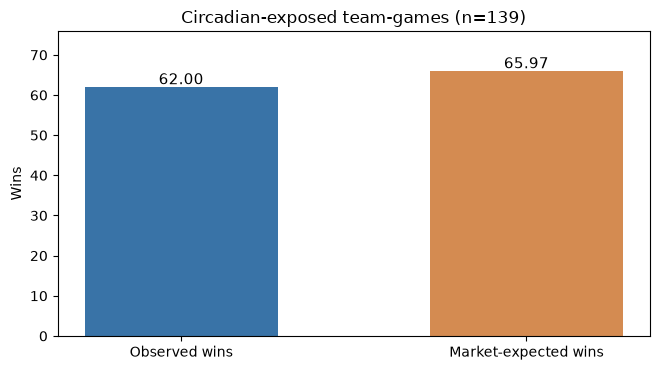

In [56]:
moneyline_data = analysis_team_game_mean.copy()
exposed_ml = moneyline_data.loc[moneyline_data["absResidualCircadianDisplacement"] > 0]
actual_wins = exposed_ml["officialWin"].astype(float).sum()
expected_wins = exposed_ml["teamMlPowerProbMean"].astype(float).sum()
fig, ax = plt.subplots(figsize=(6.7, 3.8))
bars = ax.bar(["Observed wins", "Market-expected wins"], [actual_wins, expected_wins], color=["#3973a7", "#d48b51"], width=0.56)
for bar, value in zip(bars, [actual_wins, expected_wins]):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.7, f"{value:.2f}", ha="center", fontsize=11)
ax.set(ylabel="Wins", title=f"Circadian-exposed team-games (n={len(exposed_ml)})")
ax.set_ylim(0, max(actual_wins, expected_wins)*1.15)
fig.tight_layout()
plt.show()

## 4. Regulation Tie Market Efficiency

The three-way market's regulation tie outcome is distinct from the final moneyline winner. Combined home and away travel and circadian burden are examined at game level.

### Regulation Market Schema Check

*Source: original `02_travel_reconstruction.ipynb`, code cell 439 (zero-based index). Retained without changing the statistical specification.*

In [57]:
# Identify candidate regulation-outcome and three-way market columns

candidate_cols = [
    c for c in analysis_team_game_mean.columns
    if any(
        term in c.lower()
        for term in [
            "reg",
            "tie",
            "draw",
            "three",
            "3way",
            "ot",
            "shootout"
        ]
    )
]

print("CANDIDATE COLUMNS")
for col in candidate_cols:
    print(col)

print("\nDATASET SHAPE")
print(analysis_team_game_mean.shape)

CANDIDATE COLUMNS
shotsOnGoalFor
shotsOnGoalAgainst
nonShootoutWin
shotDifferential
regulationTie_team
shootoutGame
threewayBooks
regPowerHomeProbMean
regPowerTieProbMean
regPowerAwayProbMean
regPropHomeProbMean
regPropTieProbMean
regPropAwayProbMean
regMeanOverround
regHomeGoals
regAwayGoals
regulationHomeWin
regulationTie_market
regulationAwayWin
teamRegPowerWinProbMean
opponentRegPowerWinProbMean
teamRegPropWinProbMean
opponentRegPropWinProbMean

DATASET SHAPE
(2624, 106)


### Regulation Tie Baseline QA

*Source: original `02_travel_reconstruction.ipynb`, code cell 440 (zero-based index). Retained without changing the statistical specification.*

In [58]:
# One observation per game
reg = (
    analysis_team_game_mean
    .loc[
        analysis_team_game_mean["home_or_away"] == "HOME"
    ]
    .copy()
)

cols = [
    "regulationTie_market",
    "regulationTie_team",
    "regulationHomeWin",
    "regulationAwayWin",
    "regPowerHomeProbMean",
    "regPowerTieProbMean",
    "regPowerAwayProbMean",
    "regPropTieProbMean",
    "threewayBooks"
]

print("REGULATION MARKET DATA QA")
print("Games:", len(reg))
print("Unique games:", reg["gameId"].nunique())

print("\nMISSING VALUES")
print(reg[cols].isna().sum())

print("\nREGULATION OUTCOME COUNTS")
for c in [
    "regulationHomeWin",
    "regulationTie_market",
    "regulationAwayWin"
]:
    print(c, reg[c].value_counts(dropna=False).to_dict())

# Verify outcome definitions agree
tie_agreement = (
    reg["regulationTie_market"].astype(float)
    == reg["regulationTie_team"].astype(float)
)

print("\nTie indicators disagree:",
      (~tie_agreement).sum())

# Three mutually exclusive regulation outcomes
outcome_sum = (
    reg["regulationHomeWin"].astype(float)
    + reg["regulationTie_market"].astype(float)
    + reg["regulationAwayWin"].astype(float)
)

print("Games without exactly one regulation outcome:",
      (~np.isclose(outcome_sum, 1)).sum())

# Three-way probabilities must sum to 1
prob_sum = (
    reg["regPowerHomeProbMean"].astype(float)
    + reg["regPowerTieProbMean"].astype(float)
    + reg["regPowerAwayProbMean"].astype(float)
)

print("Games with probabilities not summing to 1:",
      (~np.isclose(prob_sum, 1, atol=1e-8)).sum())

print("\nBOOKMAKER COVERAGE")
print(reg["threewayBooks"].describe())

# Actual vs market-expected regulation ties
actual_ties = reg["regulationTie_market"].astype(float).sum()
expected_ties = reg["regPowerTieProbMean"].astype(float).sum()

print("\nACTUAL VS EXPECTED REGULATION TIES")
print("Actual ties:", actual_ties)
print("Expected ties:", round(expected_ties, 4))
print("Actual tie rate:", round(actual_ties / len(reg), 4))
print("Expected tie rate:", round(expected_ties / len(reg), 4))
print("Ties minus expected:", round(actual_ties - expected_ties, 4))

REGULATION MARKET DATA QA
Games: 1312
Unique games: 1312

MISSING VALUES
regulationTie_market    0
regulationTie_team      0
regulationHomeWin       0
regulationAwayWin       0
regPowerHomeProbMean    0
regPowerTieProbMean     0
regPowerAwayProbMean    0
regPropTieProbMean      0
threewayBooks           0
dtype: int64

REGULATION OUTCOME COUNTS
regulationHomeWin {0: 720, 1: 592}
regulationTie_market {0: 1041, 1: 271}
regulationAwayWin {0: 863, 1: 449}

Tie indicators disagree: 0
Games without exactly one regulation outcome: 0
Games with probabilities not summing to 1: 0

BOOKMAKER COVERAGE
count    1312.000000
mean       16.459604
std         1.808080
min        13.000000
25%        15.000000
50%        17.000000
75%        18.000000
max        19.000000
Name: threewayBooks, dtype: float64

ACTUAL VS EXPECTED REGULATION TIES
Actual ties: 271.0
Expected ties: 276.9856
Actual tie rate: 0.2066
Expected tie rate: 0.2111
Ties minus expected: -5.9856


### Regulation Tie Exposure Construction

*Source: original `02_travel_reconstruction.ipynb`, code cell 441 (zero-based index). Retained without changing the statistical specification.*

In [59]:
source = analysis_team_game_mean.copy()

home = source.loc[
    source["home_or_away"] == "HOME",
    [
        "gameId",
        "regulationTie_market",
        "regPowerTieProbMean",
        "travelDistanceKm",
        "absResidualCircadianDisplacement"
    ]
].rename(columns={
    "travelDistanceKm": "homeTravelKm",
    "absResidualCircadianDisplacement": "homeCircadian"
})

away = source.loc[
    source["home_or_away"] == "AWAY",
    [
        "gameId",
        "travelDistanceKm",
        "absResidualCircadianDisplacement"
    ]
].rename(columns={
    "travelDistanceKm": "awayTravelKm",
    "absResidualCircadianDisplacement": "awayCircadian"
})

tie_games = home.merge(
    away,
    on="gameId",
    validate="one_to_one"
)

numeric_cols = [
    "regulationTie_market",
    "regPowerTieProbMean",
    "homeTravelKm",
    "awayTravelKm",
    "homeCircadian",
    "awayCircadian"
]

for col in numeric_cols:
    tie_games[col] = pd.to_numeric(
        tie_games[col], errors="coerce"
    )

tie_games["totalCircadianHours"] = (
    tie_games["homeCircadian"]
    + tie_games["awayCircadian"]
)

tie_games["totalTravel1000"] = (
    tie_games["homeTravelKm"]
    + tie_games["awayTravelKm"]
) / 1000

tie_games["anyCircadian"] = (
    tie_games["totalCircadianHours"] > 0
)

tie_games["tieResidual"] = (
    tie_games["regulationTie_market"]
    - tie_games["regPowerTieProbMean"]
)

print("GAME-LEVEL QA")
print("Games:", len(tie_games))
print("Unique games:", tie_games["gameId"].nunique())
print("Missing total travel:",
      tie_games["totalTravel1000"].isna().sum())
print("Missing total circadian:",
      tie_games["totalCircadianHours"].isna().sum())

print("\nCIRCADIAN EXPOSURE COUNTS")
print(tie_games["anyCircadian"].value_counts())

summary = tie_games.groupby("anyCircadian").agg(
    games=("gameId", "size"),
    actual_ties=("regulationTie_market", "sum"),
    expected_ties=("regPowerTieProbMean", "sum"),
    actual_tie_rate=("regulationTie_market", "mean"),
    expected_tie_rate=("regPowerTieProbMean", "mean"),
    ties_minus_expected=("tieResidual", "sum")
)

print("\nACTUAL VS EXPECTED TIES BY EXPOSURE")
print(summary.round(4).to_string())

GAME-LEVEL QA
Games: 1312
Unique games: 1312
Missing total travel: 20
Missing total circadian: 0

CIRCADIAN EXPOSURE COUNTS
anyCircadian
False    1186
True      126
Name: count, dtype: int64

ACTUAL VS EXPECTED TIES BY EXPOSURE
              games  actual_ties  expected_ties  actual_tie_rate  expected_tie_rate  ties_minus_expected
anyCircadian                                                                                            
False          1186          241       250.4744           0.2032             0.2112              -9.4744
True            126           30        26.5112           0.2381             0.2104               3.4888


### Regulation Tie Market Calibration: Simulation Test

*Source: original `02_travel_reconstruction.ipynb`, code cell 442 (zero-based index). Retained without changing the statistical specification.*

In [60]:
rng = np.random.default_rng(2026)
n_sim = 100_000

results = []

for exposed, group in tie_games.groupby("anyCircadian"):
    p = group["regPowerTieProbMean"].to_numpy(dtype=float)
    y = group["regulationTie_market"].to_numpy(dtype=int)

    observed = int(y.sum())
    expected = float(p.sum())
    deviation = observed - expected

    # Simulate regulation-tie outcomes under market probabilities
    simulated = np.empty(n_sim, dtype=int)

    for start in range(0, n_sim, 1000):
        end = min(start + 1000, n_sim)

        draws = (
            rng.random((end - start, len(p))) < p
        )

        simulated[start:end] = draws.sum(axis=1)

    sim_deviation = simulated - expected

    p_value = (
        np.sum(np.abs(sim_deviation) >= abs(deviation)) + 1
    ) / (n_sim + 1)

    results.append({
        "circadian_exposed": bool(exposed),
        "games": len(group),
        "actual_ties": observed,
        "expected_ties": expected,
        "ties_minus_expected": deviation,
        "null_sd": np.sqrt(np.sum(p * (1 - p))),
        "two_sided_p": p_value,
        "null_2.5pct": np.quantile(simulated, 0.025),
        "null_97.5pct": np.quantile(simulated, 0.975)
    })

tie_test_results = pd.DataFrame(results)

print("REGULATION-TIE CALIBRATION TESTS")
print(tie_test_results.round(4).to_string(index=False))

REGULATION-TIE CALIBRATION TESTS
 circadian_exposed  games  actual_ties  expected_ties  ties_minus_expected  null_sd  two_sided_p  null_2.5pct  null_97.5pct
             False   1186          241       250.4744              -9.4744  14.0488       0.5194        223.0         278.0
              True    126           30        26.5112               3.4888   4.5723       0.5077         18.0          36.0


### Regulation Tie Analysis: Market Adjusted Logistic Regression

*Source: original `02_travel_reconstruction.ipynb`, code cell 443 (zero-based index). Retained without changing the statistical specification.*

In [61]:
tie_model_df = tie_games.dropna(
    subset=[
        "regulationTie_market",
        "regPowerTieProbMean",
        "totalTravel1000",
        "totalCircadianHours"
    ]
).copy()

tie_model_df["tie"] = (
    tie_model_df["regulationTie_market"].astype(int)
)

tie_model_df["marketTieProb"] = (
    tie_model_df["regPowerTieProbMean"].astype(float)
)

tie_model_df["totalTravel1000"] = (
    tie_model_df["totalTravel1000"].astype(float)
)

tie_model_df["totalCircadianHours"] = (
    tie_model_df["totalCircadianHours"].astype(float)
)

# Validate the probability offset
assert tie_model_df["marketTieProb"].between(
    0, 1, inclusive="neither"
).all()

tie_model_df["marketTieLogOdds"] = np.log(
    tie_model_df["marketTieProb"]
    / (1 - tie_model_df["marketTieProb"])
)

X = sm.add_constant(
    tie_model_df[
        ["totalTravel1000", "totalCircadianHours"]
    ]
)

model = sm.GLM(
    tie_model_df["tie"],
    X,
    family=sm.families.Binomial(),
    offset=tie_model_df["marketTieLogOdds"]
)

result = model.fit(cov_type="HC1")

results_table = pd.DataFrame({
    "coefficient": result.params,
    "odds_ratio": np.exp(result.params),
    "p_value": result.pvalues,
    "CI_lower": result.conf_int()[0],
    "CI_upper": result.conf_int()[1]
})

print("MARKET-CONDITIONED REGULATION-TIE MODEL")
print("Games:", len(tie_model_df))
print("Unique games:", tie_model_df["gameId"].nunique())

print("\nCOEFFICIENTS")
print(results_table.round(4).to_string())

print("\nQA")
print(
    "Games with nonzero circadian burden:",
    (tie_model_df["totalCircadianHours"] > 0).sum()
)
print(
    "Games with nonzero travel burden:",
    (tie_model_df["totalTravel1000"] > 0).sum()
)

MARKET-CONDITIONED REGULATION-TIE MODEL
Games: 1292
Unique games: 1292

COEFFICIENTS
                     coefficient  odds_ratio  p_value  CI_lower  CI_upper
const                    -0.1077      0.8979   0.3044   -0.3133    0.0979
totalTravel1000           0.0475      1.0487   0.3380   -0.0497    0.1447
totalCircadianHours       0.0301      1.0306   0.8875   -0.3868    0.4470

QA
Games with nonzero circadian burden: 124
Games with nonzero travel burden: 1286


### Regulation Tie Findings: Interpretation

Across the full regulation tie sample, 271 ties occurred versus approximately 276.99 expected from the three-way market. In the exposed subset, 30 ties occurred versus approximately 26.51 expected; the simulation did not indicate a meaningful departure from the market baseline (p ≈ 0.508). Market conditioned coefficients for total travel (p ≈ 0.338) and total circadian burden (p ≈ 0.888) were also not statistically significant.

## 5. Puck Line Contract Settlement & Market Efficiency

Contracts are preserved separately by handicap magnitude. ±1.5 is the primary push-free market; ±2.5 and push-aware ±1.0 are explicitly exploratory.

### Puck-line schema QA

*Source: original `02_travel_reconstruction.ipynb`, code cell 444 (zero-based index). Retained without changing the statistical specification.*

In [62]:
pl = analysis_puckline_team.copy()

print("PUCK-LINE DATASET")
print("Rows:", len(pl))
print("Games:", pl["gameId"].nunique())
print("Columns:", len(pl.columns))

print("\nALL COLUMNS")
for col in pl.columns:
    print(col)

print("\nPOTENTIAL CONTRACT / SETTLEMENT COLUMNS")
for col in pl.columns:
    if any(
        term in col.lower()
        for term in [
            "line", "handicap", "cover", "push",
            "settle", "prob", "power", "prop",
            "book", "result"
        ]
    ):
        print(col)

PUCK-LINE DATASET
Rows: 4848
Games: 1312
Columns: 122

ALL COLUMNS
gameId
gameDate_team
season
team
opposingTeam
home_or_away
goalsFor
goalsAgainst
xGoalsFor
xGoalsAgainst
shotsOnGoalFor
shotsOnGoalAgainst
corsiPercentage
fenwickPercentage
goalDifferential
xGoalDifferential
nonShootoutWin
previousGameDate
daysBetweenGames
restDays
backToBack
shotDifferential
venue
neutralSite
startTimeUTC
venueUTCOffset
venueTimezone
awayTeam
homeTeam
awayScore
homeScore
periodType
regulationTie_team
overtimeGame
shootoutGame
winnerTeam
officialWin
city
latitude
longitude
previousVenue
previousCity
previousLatitude
previousLongitude
travelDistanceKm
previousVenueTimezone
previousVenueUTCOffset
previousVenueOffsetAtCurrentGame
currentVenueOffsetAtCurrentGame
timezoneDisplacementHours
timeZonesCrossed
travelDirection
previousHomeOrAway
officialTravelSequence
homeVenue
atHomeBase
previousAtHomeBase
physicalTravelSequence
estimatedFlightHours
departureRule
previousStartTimeUTC
departureUTC
physicalRelocati

### Puck Line Settlement Validation

*Source: original `02_travel_reconstruction.ipynb`, code cell 445 (zero-based index). Retained without changing the statistical specification.*

In [63]:
pl = analysis_puckline_team.copy()

pl["goalDifferential"] = pd.to_numeric(
    pl["goalDifferential"], errors="coerce"
)

pl["teamPuckLine"] = pd.to_numeric(
    pl["teamPuckLine"], errors="coerce"
)

pl["teamPuckPowerProb"] = pd.to_numeric(
    pl["teamPuckPowerProb"], errors="coerce"
)

pl["adjustedMargin"] = (
    pl["goalDifferential"] + pl["teamPuckLine"]
)

pl["settlement"] = np.select(
    [
        pl["adjustedMargin"] > 1e-9,
        pl["adjustedMargin"] < -1e-9
    ],
    ["cover", "loss"],
    default="push"
)

print("PUCK-LINE CONTRACTS")
print(
    pl["teamPuckLine"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nSETTLEMENT BY HANDICAP")
print(
    pd.crosstab(
        pl["teamPuckLine"],
        pl["settlement"]
    )
)

print("\nMARKET PROBABILITY QA")
print("Missing probabilities:",
      pl["teamPuckPowerProb"].isna().sum())

print("Probabilities outside (0, 1):",
      (~pl["teamPuckPowerProb"].between(
          0, 1, inclusive="neither"
      )).sum())

print("\nGAME-CONTRACT QA")
contract_checks = pl.groupby(
    ["gameId", "line"]
).agg(
    rows=("team", "size"),
    handicap_sum=("teamPuckLine", "sum"),
    probability_sum=("teamPuckPowerProb", "sum"),
    pushes=("settlement", lambda s: (s == "push").sum()),
    covers=("settlement", lambda s: (s == "cover").sum()),
    losses=("settlement", lambda s: (s == "loss").sum())
)

print("Contracts:", len(contract_checks))
print("Contracts without two team rows:",
      (contract_checks["rows"] != 2).sum())
print("Contracts with non-opposing handicaps:",
      (~np.isclose(
          contract_checks["handicap_sum"], 0
      )).sum())
print("Contracts with probabilities not summing to 1:",
      (~np.isclose(
          contract_checks["probability_sum"], 1,
          atol=1e-8
      )).sum())

print("\nCONTRACT SETTLEMENT PATTERNS")
print(
    contract_checks[
        ["pushes", "covers", "losses"]
    ].value_counts()
)

print("\nBOOKMAKER COVERAGE")
print(pl["puckLineBooks"].describe())

PUCK-LINE CONTRACTS
teamPuckLine
-2.5      26
-2.0      30
-1.5    1361
-1.0    1007
 1.0    1007
 1.5    1361
 2.0      30
 2.5      26
Name: count, dtype: int64

SETTLEMENT BY HANDICAP
settlement    cover  loss  push
teamPuckLine                   
-2.5              7    19     0
-2.0             10    13     7
-1.5            530   831     0
-1.0            383   446   178
 1.0            446   383   178
 1.5            831   530     0
 2.0             13    10     7
 2.5             19     7     0

MARKET PROBABILITY QA
Missing probabilities: 0
Probabilities outside (0, 1): 0

GAME-CONTRACT QA
Contracts: 2424
Contracts without two team rows: 0
Contracts with non-opposing handicaps: 0
Contracts with probabilities not summing to 1: 0

CONTRACT SETTLEMENT PATTERNS
pushes  covers  losses
0       1       1         2239
2       0       0          185
Name: count, dtype: int64

BOOKMAKER COVERAGE
count    4848.000000
mean        3.000825
std         1.893165
min         1.000000
25%      

### ±1.5 Puck Line Calibration

*Source: original `02_travel_reconstruction.ipynb`, code cell 446 (zero-based index). Retained without changing the statistical specification.*

In [64]:
# Restrict to push-free ±1.5 contracts
pl15 = pl.loc[
    (pl["home_or_away"] == "HOME")
    & np.isclose(pl["teamPuckLine"].abs(), 1.5)
].copy()

pl15["cover"] = (
    pl15["settlement"] == "cover"
).astype(int)

pl15["marketCoverProb"] = (
    pl15["teamPuckPowerProb"].astype(float)
)

pl15["coverResidual"] = (
    pl15["cover"] - pl15["marketCoverProb"]
)

print("PRIMARY PUCK-LINE SAMPLE")
print("Contracts:", len(pl15))
print("Unique games:", pl15["gameId"].nunique())
print("Duplicate game-contracts:",
      pl15.duplicated(["gameId", "line"]).sum())

print("\nHANDICAP DISTRIBUTION")
print(pl15["teamPuckLine"].value_counts().sort_index())

print("\nMARKET CALIBRATION")
print("Actual home covers:", pl15["cover"].sum())
print("Expected home covers:",
      round(pl15["marketCoverProb"].sum(), 4))
print("Actual cover rate:",
      round(pl15["cover"].mean(), 4))
print("Expected cover rate:",
      round(pl15["marketCoverProb"].mean(), 4))
print("Covers minus expected:",
      round(pl15["coverResidual"].sum(), 4))

print("\nCOVER RESIDUAL BY HOME HANDICAP")
print(
    pl15.groupby("teamPuckLine").agg(
        contracts=("gameId", "size"),
        actual_covers=("cover", "sum"),
        expected_covers=("marketCoverProb", "sum"),
        residual=("coverResidual", "sum")
    ).round(4).to_string()
)

print("\nBOOKMAKER COVERAGE")
print(pl15["puckLineBooks"].describe().round(2))

PRIMARY PUCK-LINE SAMPLE
Contracts: 1361
Unique games: 1301
Duplicate game-contracts: 0

HANDICAP DISTRIBUTION
teamPuckLine
-1.5    825
 1.5    536
Name: count, dtype: int64

MARKET CALIBRATION
Actual home covers: 694
Expected home covers: 662.5409
Actual cover rate: 0.5099
Expected cover rate: 0.4868
Covers minus expected: 31.4591

COVER RESIDUAL BY HOME HANDICAP
              contracts  actual_covers  expected_covers  residual
teamPuckLine                                                     
-1.5                825            344         319.3069   24.6931
 1.5                536            350         343.2339    6.7661

BOOKMAKER COVERAGE
count    1361.00
mean        4.52
std         0.99
min         1.00
25%         4.00
50%         5.00
75%         5.00
max         6.00
Name: puckLineBooks, dtype: float64


### ±1.5 Puck Line Within Game Contract QA

*Source: original `02_travel_reconstruction.ipynb`, code cell 447 (zero-based index). Retained without changing the statistical specification.*

In [65]:
contracts_per_game = (
    pl15.groupby("gameId")
    .size()
    .rename("n_contracts")
)

print("CONTRACTS PER GAME")
print(
    contracts_per_game
    .value_counts()
    .sort_index()
)

print("\nGAMES WITH MULTIPLE ±1.5 CONTRACTS")
multi_ids = contracts_per_game[
    contracts_per_game > 1
].index

multi = pl15.loc[
    pl15["gameId"].isin(multi_ids),
    [
        "gameId",
        "teamPuckLine",
        "goalDifferential",
        "cover",
        "marketCoverProb"
    ]
].sort_values(
    ["gameId", "teamPuckLine"]
)

print("Number of multi-contract games:", len(multi_ids))
print("Rows in multi-contract games:", len(multi))

print("\nHANDICAP COMBINATIONS")
print(
    multi.groupby("gameId")["teamPuckLine"]
    .apply(lambda x: tuple(sorted(x)))
    .value_counts()
)

print("\nEXAMPLE MULTI-CONTRACT GAMES")
print(multi.head(12).to_string(index=False))

print("\nGAME-LEVEL RESIDUAL SUMMARY")
game_residuals = (
    pl15.groupby("gameId")
    .agg(
        contracts=("cover", "size"),
        residual_sum=("coverResidual", "sum")
    )
)

print(game_residuals.describe().round(4))

CONTRACTS PER GAME
n_contracts
1    1241
2      60
Name: count, dtype: int64

GAMES WITH MULTIPLE ±1.5 CONTRACTS
Number of multi-contract games: 60
Rows in multi-contract games: 120

HANDICAP COMBINATIONS
teamPuckLine
(-1.5, 1.5)    60
Name: count, dtype: int64

EXAMPLE MULTI-CONTRACT GAMES
    gameId  teamPuckLine  goalDifferential  cover  marketCoverProb
2024020012          -1.5              -2.0      0         0.283437
2024020012           1.5              -2.0      0         0.702375
2024020025          -1.5               3.0      1         0.291674
2024020025           1.5               3.0      1         0.697579
2024020043          -1.5               1.0      0         0.296205
2024020043           1.5               1.0      1         0.708326
2024020065          -1.5              -1.0      0         0.283437
2024020065           1.5              -1.0      1         0.706491
2024020143          -1.5              -2.0      0         0.304933
2024020143           1.5              

### ±1.5 Puck Line Game Level Calibration Inference

*Source: original `02_travel_reconstruction.ipynb`, code cell 448 (zero-based index). Retained without changing the statistical specification.*

In [66]:
# One residual per game, summing across available contracts
pl_game_residuals = (
    pl15.groupby("gameId", as_index=False)
    .agg(
        residual_sum=("coverResidual", "sum"),
        contracts=("cover", "size")
    )
)

# Test whether mean game-level residual differs from zero
X = np.ones((len(pl_game_residuals), 1))

calibration_model = sm.OLS(
    pl_game_residuals["residual_sum"].astype(float),
    X
).fit(cov_type="HC1")

mean_residual = float(calibration_model.params.iloc[0])
se = float(calibration_model.bse.iloc[0])
p_value = float(calibration_model.pvalues.iloc[0])

ci = calibration_model.conf_int().iloc[0]

print("PUCK-LINE CALIBRATION: GAME-LEVEL INFERENCE")
print("Unique games:", len(pl_game_residuals))
print("Total contracts:", pl_game_residuals["contracts"].sum())

print("\nCALIBRATION RESULTS")
print("Total covers minus expected:",
      round(pl_game_residuals["residual_sum"].sum(), 4))
print("Mean residual per game:",
      round(mean_residual, 5))
print("Robust SE:", round(se, 5))
print("95% CI for mean residual:",
      tuple(np.round(ci.to_numpy(), 5)))
print("Two-sided p-value:", round(p_value, 5))

print("\nQA")
print(
    "Total residual matches contract-level result:",
    np.isclose(
        pl_game_residuals["residual_sum"].sum(),
        pl15["coverResidual"].sum()
    )
)

PUCK-LINE CALIBRATION: GAME-LEVEL INFERENCE
Unique games: 1301
Total contracts: 1361

CALIBRATION RESULTS
Total covers minus expected: 31.4591
Mean residual per game: 0.02418
Robust SE: 0.014
95% CI for mean residual: (np.float64(-0.00327), np.float64(0.05163))
Two-sided p-value: 0.0842

QA
Total residual matches contract-level result: True


### ±1.5 Puck Line Market Adjusted Logistic Regression

*Source: original `02_travel_reconstruction.ipynb`, code cell 449 (zero-based index). Retained without changing the statistical specification.*

In [67]:
# One away-team exposure record per game
away_exposures = (
    analysis_team_game_mean.loc[
        analysis_team_game_mean["home_or_away"] == "AWAY",
        [
            "gameId",
            "travelDistanceKm",
            "absResidualCircadianDisplacement"
        ]
    ]
    .rename(columns={
        "travelDistanceKm": "awayTravelKm",
        "absResidualCircadianDisplacement": "awayCircadian"
    })
)

# Home perspective already retained in pl15
pl_model = pl15.merge(
    away_exposures,
    on="gameId",
    how="left",
    validate="many_to_one"
)

for col in [
    "travelDistanceKm",
    "awayTravelKm",
    "absResidualCircadianDisplacement",
    "awayCircadian",
    "marketCoverProb"
]:
    pl_model[col] = pd.to_numeric(
        pl_model[col],
        errors="coerce"
    )

pl_model["travelDifference1000"] = (
    pl_model["travelDistanceKm"]
    - pl_model["awayTravelKm"]
) / 1000

pl_model["circadianDifference"] = (
    pl_model["absResidualCircadianDisplacement"]
    - pl_model["awayCircadian"]
)

pl_model = pl_model.dropna(
    subset=[
        "cover",
        "marketCoverProb",
        "travelDifference1000",
        "circadianDifference"
    ]
).copy()

assert pl_model["marketCoverProb"].between(
    0, 1, inclusive="neither"
).all()

pl_model["marketLogOdds"] = np.log(
    pl_model["marketCoverProb"]
    / (1 - pl_model["marketCoverProb"])
)

X = sm.add_constant(
    pl_model[
        ["travelDifference1000", "circadianDifference"]
    ]
)

model = sm.GLM(
    pl_model["cover"].astype(int),
    X,
    family=sm.families.Binomial(),
    offset=pl_model["marketLogOdds"]
)

result = model.fit(
    cov_type="cluster",
    cov_kwds={"groups": pl_model["gameId"]}
)

results_table = pd.DataFrame({
    "coefficient": result.params,
    "odds_ratio": np.exp(result.params),
    "p_value": result.pvalues,
    "CI_lower": result.conf_int()[0],
    "CI_upper": result.conf_int()[1]
})

print("MARKET-CONDITIONED ±1.5 PUCK-LINE MODEL")
print("Contracts:", len(pl_model))
print("Unique games:", pl_model["gameId"].nunique())

print("\nCOEFFICIENTS")
print(results_table.round(4).to_string())

print("\nQA")
print(
    "Contracts in games with nonzero circadian difference:",
    (pl_model["circadianDifference"] != 0).sum()
)
print(
    "Contracts in games with nonzero travel difference:",
    (pl_model["travelDifference1000"] != 0).sum()
)
print(
    "Games with multiple retained contracts:",
    (pl_model.groupby("gameId").size() > 1).sum()
)

MARKET-CONDITIONED ±1.5 PUCK-LINE MODEL
Contracts: 1340
Unique games: 1281

COEFFICIENTS
                      coefficient  odds_ratio  p_value  CI_lower  CI_upper
const                      0.1423      1.1529   0.0216    0.0209    0.2637
travelDifference1000       0.0754      1.0783   0.1134   -0.0179    0.1686
circadianDifference       -0.1786      0.8365   0.5483   -0.7615    0.4044

QA
Contracts in games with nonzero circadian difference: 119
Contracts in games with nonzero travel difference: 1296
Games with multiple retained contracts: 59


### Proportional De-vig Sensitivity

*Source: original `02_travel_reconstruction.ipynb`, code cell 450 (zero-based index). Retained without changing the statistical specification.*

In [68]:
# Same observations and exposure variables as primary model
pl_prop = pl_model.copy()

pl_prop["propMarketProb"] = pd.to_numeric(
    pl_prop["teamPuckPropProb"],
    errors="coerce"
)

assert pl_prop["propMarketProb"].notna().all()
assert pl_prop["propMarketProb"].between(
    0, 1, inclusive="neither"
).all()

pl_prop["propMarketLogOdds"] = np.log(
    pl_prop["propMarketProb"]
    / (1 - pl_prop["propMarketProb"])
)

X_prop = sm.add_constant(
    pl_prop[
        ["travelDifference1000", "circadianDifference"]
    ]
)

prop_model = sm.GLM(
    pl_prop["cover"].astype(int),
    X_prop,
    family=sm.families.Binomial(),
    offset=pl_prop["propMarketLogOdds"]
)

prop_result = prop_model.fit(
    cov_type="cluster",
    cov_kwds={"groups": pl_prop["gameId"]}
)

comparison = pd.DataFrame({
    "power_coef": result.params,
    "power_p": result.pvalues,
    "proportional_coef": prop_result.params,
    "proportional_p": prop_result.pvalues
})

print("PUCK-LINE DE-VIGGING SENSITIVITY")
print("Contracts:", len(pl_prop))
print("Unique games:", pl_prop["gameId"].nunique())

print("\nPOWER VS PROPORTIONAL")
print(comparison.round(4).to_string())

print("\nPROPORTIONAL 95% CONFIDENCE INTERVALS")
print(prop_result.conf_int().round(4).to_string())

PUCK-LINE DE-VIGGING SENSITIVITY
Contracts: 1340
Unique games: 1281

POWER VS PROPORTIONAL
                      power_coef  power_p  proportional_coef  proportional_p
const                     0.1423   0.0216             0.1375          0.0248
travelDifference1000      0.0754   0.1134             0.0751          0.1110
circadianDifference      -0.1786   0.5483            -0.1795          0.5423

PROPORTIONAL 95% CONFIDENCE INTERVALS
                           0       1
const                 0.0175  0.2576
travelDifference1000 -0.0173  0.1675
circadianDifference  -0.7570  0.3980


### Primary Puck Line Findings: Interpretation

For ±1.5 contracts, the primary calibration sample contained 1,361 contracts across 1,301 games. There were 694 observed home covers versus approximately 662.54 expected. The game level calibration test (p = 0.0842) did not cross the conventional 5% threshold; it is not evidence of a reliable exploitable edge. Market conditioned travel and circadian coefficients were also not statistically significant, including under the alternative proportional de-vigging sensitivity.

### Figure 3: Primary ±1.5 Puck Line Calibration

The observed versus expected gap is descriptive. The accepted game level calibration test accounts for correlated contracts within games and is not statistically significant (p = 0.0842).

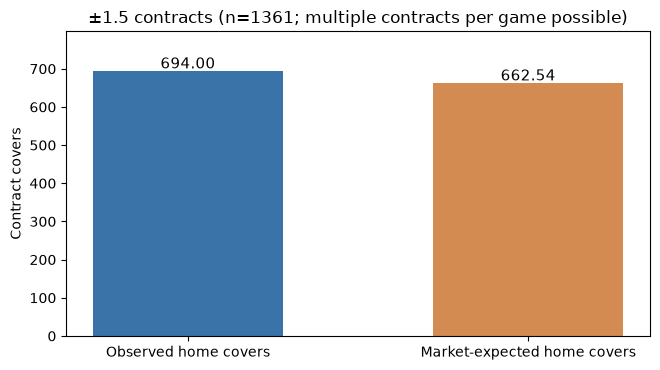

In [69]:
puck_data = analysis_puckline_team.copy()
primary = puck_data.loc[(puck_data["home_or_away"] == "HOME") & np.isclose(puck_data["teamPuckLine"].abs(), 1.5)].copy()
observed = (primary["goalDifferential"].astype(float) + primary["teamPuckLine"].astype(float) > 0).sum()
expected = primary["teamPuckPowerProb"].astype(float).sum()
fig, ax = plt.subplots(figsize=(6.7, 3.8))
bars = ax.bar(["Observed home covers", "Market-expected home covers"], [observed, expected], color=["#3973a7", "#d48b51"], width=0.56)
for bar, value in zip(bars, [observed, expected]):
    ax.text(bar.get_x()+bar.get_width()/2, value+7, f"{value:.2f}", ha="center", fontsize=11)
ax.set(ylabel="Contract covers", title=f"±1.5 contracts (n={len(primary)}; multiple contracts per game possible)")
ax.set_ylim(0, max(observed, expected)*1.15)
fig.tight_layout()
plt.show()

### ±2.5 Descriptive Audit

*Source: original `02_travel_reconstruction.ipynb`, code cell 451 (zero-based index). Retained without changing the statistical specification.*

In [70]:
pl25 = pl.loc[
    (pl["home_or_away"] == "HOME")
    & np.isclose(pl["teamPuckLine"].abs(), 2.5)
].copy()

pl25["cover"] = (
    pl25["settlement"] == "cover"
).astype(int)

pl25["marketCoverProb"] = (
    pl25["teamPuckPowerProb"].astype(float)
)

pl25["coverResidual"] = (
    pl25["cover"] - pl25["marketCoverProb"]
)

print("±2.5 PUCK-LINE CONTRACTS")
print("Contracts:", len(pl25))
print("Unique games:", pl25["gameId"].nunique())

print("\nHANDICAP DISTRIBUTION")
print(pl25["teamPuckLine"].value_counts().sort_index())

print("\nACTUAL VS EXPECTED")
print("Actual covers:", pl25["cover"].sum())
print("Expected covers:",
      round(pl25["marketCoverProb"].sum(), 4))
print("Covers minus expected:",
      round(pl25["coverResidual"].sum(), 4))

print("\nCONTRACT DETAILS")
columns = [
    "gameId",
    "gameDate_team",
    "homeTeam",
    "awayTeam",
    "teamPuckLine",
    "goalDifferential",
    "cover",
    "marketCoverProb",
    "puckLineBooks",
    "travelDistanceKm",
    "absResidualCircadianDisplacement"
]

print(
    pl25[columns]
    .sort_values(["gameDate_team", "gameId"])
    .round(4)
    .to_string(index=False)
)

±2.5 PUCK-LINE CONTRACTS
Contracts: 26
Unique games: 26

HANDICAP DISTRIBUTION
teamPuckLine
-2.5    24
 2.5     2
Name: count, dtype: int64

ACTUAL VS EXPECTED
Actual covers: 9
Expected covers: 11.862
Covers minus expected: -2.862

CONTRACT DETAILS
    gameId gameDate_team homeTeam awayTeam  teamPuckLine  goalDifferential  cover  marketCoverProb  puckLineBooks  travelDistanceKm  absResidualCircadianDisplacement
2024020212    2024-11-07      NJD      MTL          -2.5               2.0      0           0.4424              1         3244.0399                               0.0
2024020261    2024-11-14      NYR      SJS          -2.5               1.0      0           0.4473              5            0.0000                               0.0
2024020291    2024-11-18      DAL      ANA          -2.5              -2.0      0           0.4543              5         1388.7025                               0.0
2024020303    2024-11-20      DAL      SJS          -2.5               3.0      1      

### ±1.0 Puck Line Settlement and Push Audit

*Source: original `02_travel_reconstruction.ipynb`, code cell 452 (zero-based index). Retained without changing the statistical specification.*

In [71]:
pl10 = pl.loc[
    (pl["home_or_away"] == "HOME")
    & np.isclose(pl["teamPuckLine"].abs(), 1.0)
].copy()

pl10["marketCoverProb"] = pd.to_numeric(
    pl10["teamPuckPowerProb"],
    errors="coerce"
)

pl10["cover"] = (
    pl10["settlement"] == "cover"
).astype(int)

pl10["loss"] = (
    pl10["settlement"] == "loss"
).astype(int)

pl10["push"] = (
    pl10["settlement"] == "push"
).astype(int)

pl10["decisive"] = (
    pl10["push"] == 0
)

print("±1.0 PUCK-LINE SAMPLE")
print("Contracts:", len(pl10))
print("Unique games:", pl10["gameId"].nunique())
print(
    "Duplicate game-contracts:",
    pl10.duplicated(["gameId", "line"]).sum()
)

print("\nSETTLEMENT COUNTS")
print(pl10["settlement"].value_counts())

print("\nSETTLEMENT BY HOME HANDICAP")
print(
    pd.crosstab(
        pl10["teamPuckLine"],
        pl10["settlement"]
    )
)

print("\nPUSH RATE")
print(round(pl10["push"].mean(), 4))

print("\nDECISIVE CONTRACTS")
decisive = pl10.loc[pl10["decisive"]].copy()

print("Decisive contracts:", len(decisive))
print("Unique decisive games:", decisive["gameId"].nunique())

print("\nMARKET PROBABILITY QA")
print(
    "Missing probabilities:",
    pl10["marketCoverProb"].isna().sum()
)
print(
    "Probabilities outside (0, 1):",
    (~pl10["marketCoverProb"].between(
        0, 1, inclusive="neither"
    )).sum()
)

print("\nCONTRACTS PER GAME")
print(
    pl10.groupby("gameId")
    .size()
    .value_counts()
    .sort_index()
)

±1.0 PUCK-LINE SAMPLE
Contracts: 1007
Unique games: 1007
Duplicate game-contracts: 0

SETTLEMENT COUNTS
settlement
cover    425
loss     404
push     178
Name: count, dtype: int64

SETTLEMENT BY HOME HANDICAP
settlement    cover  loss  push
teamPuckLine                   
-1.0            232   253   102
 1.0            193   151    76

PUSH RATE
0.1768

DECISIVE CONTRACTS
Decisive contracts: 829
Unique decisive games: 829

MARKET PROBABILITY QA
Missing probabilities: 0
Probabilities outside (0, 1): 0

CONTRACTS PER GAME
1    1007
Name: count, dtype: int64


### ±1.0 Puck Line Circadian Exposure Audit

*Source: original `02_travel_reconstruction.ipynb`, code cell 453 (zero-based index). Retained without changing the statistical specification.*

In [72]:
# Away-team circadian exposure, one row per game
away_circadian = (
    analysis_team_game_mean.loc[
        analysis_team_game_mean["home_or_away"] == "AWAY",
        ["gameId", "absResidualCircadianDisplacement"]
    ]
    .rename(columns={
        "absResidualCircadianDisplacement": "awayCircadian"
    })
)

pl10_exposure = pl10.merge(
    away_circadian,
    on="gameId",
    how="left",
    validate="one_to_one"
)

pl10_exposure["homeCircadian"] = pd.to_numeric(
    pl10_exposure["absResidualCircadianDisplacement"],
    errors="coerce"
)

pl10_exposure["awayCircadian"] = pd.to_numeric(
    pl10_exposure["awayCircadian"],
    errors="coerce"
)

pl10_exposure["totalCircadianHours"] = (
    pl10_exposure["homeCircadian"]
    + pl10_exposure["awayCircadian"]
)

pl10_exposure["anyCircadian"] = (
    pl10_exposure["totalCircadianHours"] > 0
)

print("CIRCADIAN EXPOSURE QA")
print("Contracts:", len(pl10_exposure))
print("Unique games:", pl10_exposure["gameId"].nunique())
print(
    "Missing circadian burden:",
    pl10_exposure["totalCircadianHours"].isna().sum()
)

print("\nPUSH FREQUENCY BY CIRCADIAN EXPOSURE")

push_summary = (
    pl10_exposure.groupby("anyCircadian")
    .agg(
        contracts=("gameId", "size"),
        pushes=("push", "sum"),
        push_rate=("push", "mean"),
        mean_circadian_hours=("totalCircadianHours", "mean")
    )
)

print(push_summary.round(4).to_string())

print("\nPUSH FREQUENCY BY HOME HANDICAP")
print(
    pl10_exposure.groupby("teamPuckLine")
    .agg(
        contracts=("gameId", "size"),
        pushes=("push", "sum"),
        push_rate=("push", "mean")
    ).round(4).to_string()
)

CIRCADIAN EXPOSURE QA
Contracts: 1007
Unique games: 1007
Missing circadian burden: 0

PUSH FREQUENCY BY CIRCADIAN EXPOSURE
              contracts  pushes  push_rate  mean_circadian_hours
anyCircadian                                                    
False               919     160     0.1741                0.0000
True                 88      18     0.2045                0.6985

PUSH FREQUENCY BY HOME HANDICAP
              contracts  pushes  push_rate
teamPuckLine                              
-1.0                587     102     0.1738
 1.0                420      76     0.1810


### ±1.0 Puck Line Conditional Cover Calibration

*Source: original `02_travel_reconstruction.ipynb`, code cell 454 (zero-based index). Retained without changing the statistical specification.*

In [73]:
pl10_decisive = pl10_exposure.loc[
    pl10_exposure["decisive"]
].copy()

pl10_decisive["coverResidual"] = (
    pl10_decisive["cover"]
    - pl10_decisive["marketCoverProb"]
)

print("±1.0 CONDITIONAL COVER SAMPLE")
print("Decisive contracts:", len(pl10_decisive))
print("Unique games:", pl10_decisive["gameId"].nunique())

print("\nOVERALL CONDITIONAL CALIBRATION")
print("Actual covers:", pl10_decisive["cover"].sum())
print(
    "Expected covers:",
    round(pl10_decisive["marketCoverProb"].sum(), 4)
)
print(
    "Actual cover rate:",
    round(pl10_decisive["cover"].mean(), 4)
)
print(
    "Expected cover rate:",
    round(pl10_decisive["marketCoverProb"].mean(), 4)
)
print(
    "Covers minus expected:",
    round(pl10_decisive["coverResidual"].sum(), 4)
)

print("\nBY HOME HANDICAP")
print(
    pl10_decisive.groupby("teamPuckLine").agg(
        contracts=("gameId", "size"),
        actual_covers=("cover", "sum"),
        expected_covers=("marketCoverProb", "sum"),
        residual=("coverResidual", "sum")
    ).round(4).to_string()
)

print("\nBY CIRCADIAN EXPOSURE")
print(
    pl10_decisive.groupby("anyCircadian").agg(
        contracts=("gameId", "size"),
        actual_covers=("cover", "sum"),
        expected_covers=("marketCoverProb", "sum"),
        residual=("coverResidual", "sum")
    ).round(4).to_string()
)

print("\nQA")
print(
    "Any pushes retained:",
    (pl10_decisive["push"] == 1).any()
)
print(
    "Missing probabilities:",
    pl10_decisive["marketCoverProb"].isna().sum()
)

±1.0 CONDITIONAL COVER SAMPLE
Decisive contracts: 829
Unique games: 829

OVERALL CONDITIONAL CALIBRATION
Actual covers: 425
Expected covers: 414.3147
Actual cover rate: 0.5127
Expected cover rate: 0.4998
Covers minus expected: 10.6853

BY HOME HANDICAP
              contracts  actual_covers  expected_covers  residual
teamPuckLine                                                     
-1.0                485            232         223.7545    8.2455
 1.0                344            193         190.5602    2.4398

BY CIRCADIAN EXPOSURE
              contracts  actual_covers  expected_covers  residual
anyCircadian                                                     
False               759            384         378.6807    5.3193
True                 70             41          35.6340    5.3660

QA
Any pushes retained: False
Missing probabilities: 0


### ±1.0 Puck Line Analysis: Conditional Market-Adjusted Logistic Regression

*Source: original `02_travel_reconstruction.ipynb`, code cell 455 (zero-based index). Retained without changing the statistical specification.*

In [74]:
# Away-team travel exposure, one row per game
away_travel = (
    analysis_team_game_mean.loc[
        analysis_team_game_mean["home_or_away"] == "AWAY",
        ["gameId", "travelDistanceKm"]
    ]
    .rename(columns={
        "travelDistanceKm": "awayTravelKm"
    })
)

pl10_model = pl10_decisive.merge(
    away_travel,
    on="gameId",
    how="left",
    validate="one_to_one"
)

for col in [
    "travelDistanceKm",
    "awayTravelKm",
    "homeCircadian",
    "awayCircadian",
    "marketCoverProb"
]:
    pl10_model[col] = pd.to_numeric(
        pl10_model[col],
        errors="coerce"
    )

pl10_model["travelDifference1000"] = (
    pl10_model["travelDistanceKm"]
    - pl10_model["awayTravelKm"]
) / 1000

pl10_model["circadianDifference"] = (
    pl10_model["homeCircadian"]
    - pl10_model["awayCircadian"]
)

pl10_model = pl10_model.dropna(
    subset=[
        "cover",
        "marketCoverProb",
        "travelDifference1000",
        "circadianDifference"
    ]
).copy()

assert pl10_model["marketCoverProb"].between(
    0, 1, inclusive="neither"
).all()

pl10_model["marketLogOdds"] = np.log(
    pl10_model["marketCoverProb"]
    / (1 - pl10_model["marketCoverProb"])
)

X = sm.add_constant(
    pl10_model[
        ["travelDifference1000", "circadianDifference"]
    ]
)

model = sm.GLM(
    pl10_model["cover"].astype(int),
    X,
    family=sm.families.Binomial(),
    offset=pl10_model["marketLogOdds"]
)

pl10_result = model.fit(cov_type="HC1")

results_table = pd.DataFrame({
    "coefficient": pl10_result.params,
    "odds_ratio": np.exp(pl10_result.params),
    "p_value": pl10_result.pvalues,
    "CI_lower": pl10_result.conf_int()[0],
    "CI_upper": pl10_result.conf_int()[1]
})

print("MARKET-CONDITIONED ±1.0 PUCK-LINE MODEL")
print("Decisive contracts:", len(pl10_model))
print("Unique games:", pl10_model["gameId"].nunique())

print("\nCOEFFICIENTS")
print(results_table.round(4).to_string())

print("\nQA")
print(
    "Games with nonzero circadian difference:",
    (pl10_model["circadianDifference"] != 0).sum()
)
print(
    "Games with nonzero travel difference:",
    (pl10_model["travelDifference1000"] != 0).sum()
)
print(
    "Pushes retained:",
    pl10_model["push"].sum()
)

MARKET-CONDITIONED ±1.0 PUCK-LINE MODEL
Decisive contracts: 812
Unique games: 812

COEFFICIENTS
                      coefficient  odds_ratio  p_value  CI_lower  CI_upper
const                      0.0865      1.0903   0.2519   -0.0615    0.2344
travelDifference1000       0.0538      1.0552   0.3592   -0.0611    0.1687
circadianDifference       -0.3483      0.7059   0.3447   -1.0707    0.3741

QA
Games with nonzero circadian difference: 68
Games with nonzero travel difference: 780
Pushes retained: 0


### ±1.0 Puck Line Results and Interpretation

For exploratory ±1.0 contracts, 178 of 1,007 settlements were pushes. The remaining 829 decisive contracts produced 425 covers versus approximately 414.31 expected. The market-conditioned model uses a smaller complete-case decisive sample (812 games) and did not identify a statistically significant incremental travel or circadian association. Because the analysis conditions on non-push outcomes, its estimand differs from the push-free ±1.5 analysis.

## 6. Conclusions and Limitations

**Main finding.** In this 2024–25 NHL sample, travel distance and residual circadian displacement did not show robust, statistically detectable incremental associations with on-ice performance or with outcomes after conditioning on consensus betting market probabilities. This is a null finding under the models tested, not proof that travel has no effect, that markets are perfectly efficient, or that a trading strategy is profitable.

**Interpretive context.** Back-to-back scheduling showed a modest negative association with expected goal differential in some specifications. That secondary finding is observational and should not be interpreted causally. The puck line calibration results are similarly descriptive rather than evidence of executable betting value.

**Limitations.** The analysis covers one NHL season; nonzero circadian exposure is relatively rare. Additional limitations include potential unmeasured confounding, missing travel at the first game boundary, consensus probabilities rather than executable odds, correlated contracts, multiple exploratory comparisons, and no out-of-sample replication. The ±1.0 puck line contract analysis conditions on decisive settlements and may be affected by selection into non-push outcomes.